# 09 · Unsteady reactors, batch heat exchange and runaway

Start-up, shutdown, a coolant failure, a batch that is charged too fast: transients are where reactors are
lost. This notebook follows an exothermic batch reactor with jacket cooling to its temperature peak, finds the
cooling below which it runs away, applies Semenov's criterion for thermal explosion, and simulates a CSTR
coolant failure - the calculations behind a reactor's safety case.

**What you will learn**
- simulate batch reactors with jacket cooling and locate the runaway boundary
- apply Semenov's criterion
- compute the adiabatic time to maximum rate
- analyse a CSTR coolant failure

**Before you start:** notebook 08  ·  **Time:** about 60-75 min

In [1]:
try:                      # on Google Colab (or anywhere engreact is missing): install it from GitHub
    import engreact
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/engreact"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from engreact import energy, kinetics
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## A batch reactor with a cooling jacket

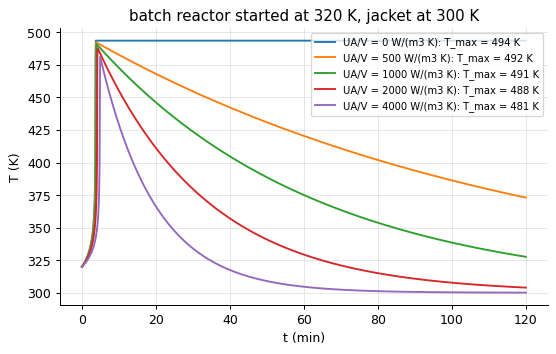

In [2]:
k0, Ea, dH, C_A0, cp_vol = 5.0e7, 68e3, -250e3, 2500.0, 3.6e6
t = np.linspace(0, 7200, 1441)
fig, ax = plt.subplots()
for UA_V in (0.0, 500.0, 1000.0, 2000.0, 4000.0):
    b = energy.batch_with_heat_exchange(k0, Ea, dH, C_A0, 320.0, cp_vol, UA_V, T_a=300.0, t=t)
    ax.plot(t / 60, b["T"], label=f"UA/V = {UA_V:.0f} W/(m3 K): T_max = {b['T_max']:.0f} K")
ax.set(xlabel="t (min)", ylabel="T (K)", title="batch reactor started at 320 K, jacket at 300 K"); ax.legend(fontsize=8); plt.show()

Without cooling the batch reaches the full adiabatic rise (174 K); with modest cooling it still peaks near
450 K because the heat release outruns the jacket once the reaction accelerates; only strong cooling keeps
the peak small. The peak temperature, not the average, is what decomposes the product, boils the solvent or
bursts the vessel.

## The critical cooling: a sharp transition

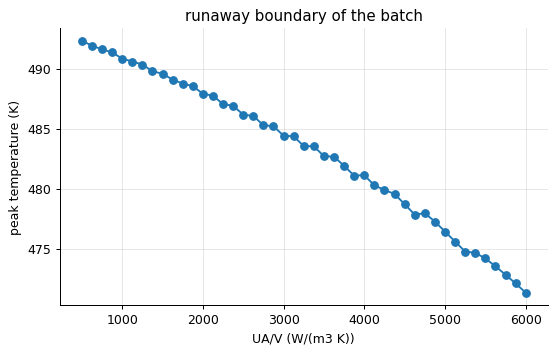

the peak temperature drops most sharply between UA/V = 4500 and 4625 W/(m3 K): the practical runaway boundary
Semenov (zero-order estimate at 320 K): critical UA/V = 53936 W/(m3 K), critical self-heating 12.5 K


In [3]:
UAs = np.linspace(500, 6000, 45)
peaks = [energy.batch_with_heat_exchange(k0, Ea, dH, C_A0, 320.0, cp_vol, ua, 300.0, t)["T_max"] for ua in UAs]
plt.plot(UAs, peaks, "o-"); plt.xlabel("UA/V (W/(m3 K))"); plt.ylabel("peak temperature (K)"); plt.title("runaway boundary of the batch"); plt.show()
i = int(np.argmax(np.abs(np.diff(peaks))))
print(f"the peak temperature drops most sharply between UA/V = {UAs[i]:.0f} and {UAs[i+1]:.0f} W/(m3 K): the practical runaway boundary")
sem = energy.semenov_critical(dH, C_A0, k0, Ea, 320.0)
print(f"Semenov (zero-order estimate at 320 K): critical UA/V = {sem['UA_over_V_critical']:.0f} W/(m3 K), critical self-heating {sem['dT_critical']:.1f} K")

The peak temperature falls by hundreds of kelvin across a narrow band of cooling capacity: runaway is a
threshold phenomenon. Semenov's criterion - heat generation at the ambient temperature times $E_a/RT_a^2$,
compared with the cooling coefficient over $e$ - gives the same order of magnitude analytically, and its
critical self-heating of $RT_a^2/E_a$ (about 12 K here) is the temperature rise above which the balance
tips. A reactor that is "only" 15 K above its jacket may already be past the point of no return.

## The adiabatic time to maximum rate

In [4]:
for T_start in (310.0, 320.0, 330.0, 340.0):
    b = energy.batch_with_heat_exchange(k0, Ea, dH, C_A0, T_start, cp_vol, 0.0, 300.0, np.linspace(0, 36000, 7201))
    i = int(np.argmax(np.gradient(b["T"])))
    print(f"start at {T_start:.0f} K: time to maximum rate {b['t'][i]/60:6.1f} min")

start at 310 K: time to maximum rate    7.7 min
start at 320 K: time to maximum rate    3.6 min
start at 330 K: time to maximum rate    1.8 min
start at 340 K: time to maximum rate    0.9 min


The time to maximum rate under adiabatic conditions (TMR$_{ad}$) is a standard safety metric from reaction
calorimetry: how long after a cooling failure the operators have before the reaction runs. It shortens
exponentially with the starting temperature - halving for every ten kelvin here - which is why the process
temperature, not just the jacket, is a safety parameter.

## CSTR coolant failure

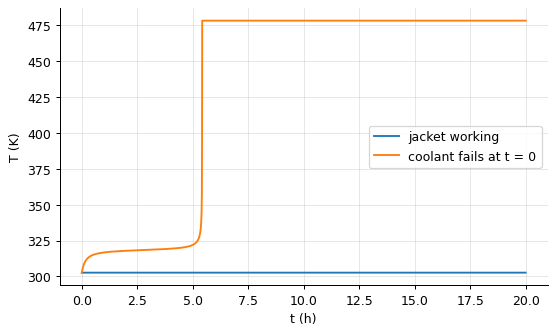

operating at 302.6 K (X = 0.022); after the coolant failure the reactor passes +50 K after 5.4 h and reaches 478 K
the adiabatic reactor at this feed temperature has a single steady state, the ignited one (notebook 08, kappa = 0): the low state no longer exists


In [5]:
tau, kappa, T_a = 240.0, 0.8, 295.0
ss = energy.cstr_steady_states(k0, Ea, dH, C_A0, 305.0, tau, cp_vol, kappa, T_a, T_range=(250.0, 800.0))
T_ss, X_ss = ss["T"][0], ss["X"][0]
t = np.linspace(0, 20 * 3600, 2401)
normal = energy.cstr_unsteady(k0, Ea, dH, C_A0, 305.0, tau, cp_vol, t, C_A0 * (1 - X_ss), T_ss, UA_over_Vcp=kappa / tau, T_a=T_a)
failed = energy.cstr_unsteady(k0, Ea, dH, C_A0, 305.0, tau, cp_vol, t, C_A0 * (1 - X_ss), T_ss, UA_over_Vcp=0.0, T_a=T_a)
plt.plot(t / 3600, normal["T"], label="jacket working"); plt.plot(t / 3600, failed["T"], label="coolant fails at t = 0"); plt.xlabel("t (h)"); plt.ylabel("T (K)"); plt.legend(); plt.show()
crossed = np.nonzero(failed["T"] > T_ss + 50)[0]
print(f"operating at {T_ss:.1f} K (X = {X_ss:.3f}); after the coolant failure the reactor" + (f" passes +50 K after {t[crossed[0]]/3600:.1f} h and reaches {failed['T'].max():.0f} K" if crossed.size else " never ignites"))
print("the adiabatic reactor at this feed temperature has a single steady state, the ignited one (notebook 08, kappa = 0): the low state no longer exists")

On the low branch the reactor looks docile: 2 % conversion, a few kelvin above the feed. Lose the jacket and
for hours almost nothing seems to happen - the temperature creeps up by a degree an hour - and then, once
the self-heating passes Semenov's critical rise, it ignites to the adiabatic state within minutes. The long,
quiet induction is the dangerous part: it looks like nothing is wrong. The safety case must ask "what if the cooling stops",
and the answer is a number of minutes to a trip - a relief valve, an emergency quench, a shutdown of the
feed - that this simulation sizes.

## Inside the algorithm: Semenov's balance

In [6]:
from engreact.constants import R
q = (-dH) * C_A0 * kinetics.arrhenius(k0, Ea, 320.0)
print("by hand: critical UA/V =", q * Ea / (R * 320.0**2) * np.e, "; library:", sem["UA_over_V_critical"])

by hand: critical UA/V = 53935.535969275945 ; library: 53935.535969275945


## Exercises
1. A semibatch alternative: feed A over 60 min into the reactor at 320 K with UA/V = 1000 W/(m3 K) (use `multiple.Network` with an energy balance added by hand, or approximate with the batch model by feeding in ten portions). How much lower is the peak temperature than the all-at-once batch?
2. Relief sizing: assume the reactor is vented when T exceeds 400 K. For the adiabatic batch started at 320 K, compute the rate of heat release (W/m3) at the moment of venting and the fraction of A still unreacted.
3. **Implement it yourself:** write the batch energy balance yourself (two ODEs) and reproduce the peak temperature for UA/V = 1000 W/(m3 K); then add a term for evaporative cooling that caps T at the solvent's boiling point.